# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhang 2019's HGSOC malignant manifold is **non-branching**: the developmental signatures collapse onto a
**single dominant axis** — gastrulation (Gast) high at one pole opposed to neural-crest (Crest) at a
terminal end, with posterior-somitogenesis (pSom) co-graded through the body — rather than a hub
radiating to discrete subtypes with cross-repression. A PPT *tree* over this compact ~2.8k-cell cloud
throws spurious forks (2–3 forks at Nodes=100–200); the geometry that matters is the signature geography:
Gast and pSom do **not** compete out of a hub (smoothed r ~ -0.10, i.e. no strong cross-repression axis)
and both oppose Crest (pSom↔Crest r ~ -0.64, Gast↔Crest r ~ -0.44) — a single (Gast/pSom)->Crest gradient
with Crest a single terminal tip. The correct topology is therefore a **principal curve** (ElPiGraph,
non-branching by construction) fit on the *joint* embedding — **not** a re-embedding (re-embedding an
anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** The manifold is one predominantly low-cycling body (~9%
cycling). A small lobe carries a mildly elevated cycling fraction (~20%), so we explicitly verify the
axis is **not** proliferation-driven: (i) the developmental gene sets barely overlap the Regev–Tirosh
S+G2M programme; (ii) the (Gast/pSom)↔Crest anti-correlations remain **clearly negative** with that lobe
removed (pSom↔Crest strengthens -0.64->-0.78; Gast↔Crest stays negative, -0.44->-0.35); (iii) pseudotime
does not track a cycling score. Whole manifold kept. The curve is rooted at the
Gast-high tip and pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`,
`manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control
pool and graph-smoothed to read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 2782 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.61
Gast: 78/81 genes present
pSom: 91/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0108, 'pSom': 0.0415, 'Crest': -0.0343}


### Scope decision — whole manifold (cell-cycle checked, not confounded)
The manifold is one body with a small mildly-cycling lobe. We verify the axis is developmental not
proliferative: (i) the developmental gene sets are essentially **cell-cycle-free** (overlap with the
Regev–Tirosh S+G2M programme); (ii) the (Gast/pSom)↔Crest anti-correlations stay clearly negative in the
whole manifold and in the low-cycling body alone (pSom↔Crest even strengthens; Gast↔Crest stays negative);
(iii) pseudotime does not track a cycling score. Whole manifold kept (no scoping).

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
body = adata[adata.obs['lobe'] != '2']
print('anti-correlation within low-cycling body only (lobe 2 removed):')
for a,b in [('Crest_sm','pSom_sm'),('Crest_sm','Gast_sm')]:
    r = np.corrcoef(body.obs[a], body.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].mean())
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.10
  Crest_sm vs Gast_sm: r = -0.44
  Crest_sm vs pSom_sm: r = -0.64
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
anti-correlation within low-cycling body only (lobe 2 removed):
  Crest_sm vs pSom_sm: r = -0.78
  Crest_sm vs Gast_sm: r = -0.35
cycling fraction: 0.090 (single low-cycling body)


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1 (minimum
distance between graph-non-adjacent nodes, in units of median edge length) certifies the curve does not
fold back on itself. `epg_mu=100` is strong bending regularisation, keeping the arc smooth.
Fold-freeness and the 2-tip / 0-fork topology are stable across Nodes = 15/20/30 — where a PPT *tree*
instead throws spurious forks on this compact cloud.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

print('PPT tree over this cloud (for contrast):')
for Nn in [100, 200]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=Nn, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
    Bt = np.asarray(a2.uns['graph']['B'])
    print(f'  PPT N={Nn}: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks (spurious)')

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

PPT tree over this cloud (for contrast):
  PPT N=100: 4 tips, 2 forks (spurious)
  PPT N=200: 5 tips, 3 forks (spurious)
curve N=15: 2 tips, 0 forks | self-approach 2.95
curve N=20: 2 tips, 0 forks | self-approach 2.88
curve N=30: 2 tips, 0 forks | self-approach 2.17
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.88 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin (Gast/pSom
are EARLY, Crest is LATE). Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} '
      '(cell-cycle-free axis; not proliferation-driven)')

tip 0: Gast=+0.0065 pSom=+0.0359 Crest=-0.0449
tip 2: Gast=-0.0216 pSom=+0.0439 Crest=-0.0294
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.502 p=2.3e-177
  pSom_sm: rho=+0.217 p=4.4e-31
  Crest_sm: rho=+0.339 p=5.4e-76
Neural-crest-high decile mean pseudotime = 0.80
Somitogenesis-high decile mean pseudotime = 0.76
Gastrulation-high decile mean pseudotime = 0.11
caveat: pseudotime vs cycling score rho = -0.25 (cell-cycle-free axis; not proliferation-driven)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal — was
derived **once in 01** (rotation angle from the manifold's axis of maximal variance; sign from the
developmental-module geography, Gast-high origin on the left) and stored as `X_umap_lin`. Every UMAP
deliverable across 01–04 re-uses these exact coordinates, so orientation is consistent by construction
(binding). Here we **verify** that layout now that pseudotime exists: the correlation of the stored
`X_umap_lin` x-axis with pseudotime must be strongly positive (low pseudotime = developmental origin on
the left).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.98
variance-axis vs pseudotime-axis disagreement = 2.3deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


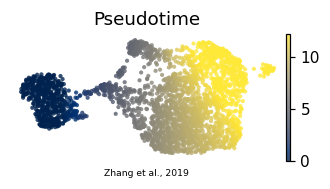

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')